# Consigne

Pour éviter la perte de données, un back-up des résultats de moulinettage est mis en place en amont de l'envoi vers la seconde file.

- Quel changement cela opère-t-il sur la proportion de pages blanches ?
- Quels problèmes peuvent surgir avec cette solution ?
- Discutez des avantages d'un back-up aléatoire plutôt que systématique.
- Calculez le temps de séjour moyen et la variance empirique dans ce modèle.

# Hypothèses

Même système qu'en partie 2, avec ks et kf des capacités totales.

En sortie de file 1, chaque résultat est sauvegardé avec une probabilité p. S'il trouve la file 2 pleine, un résultat sauvegardé attend dans le back-up, un résultat non sauvegardé est perdu. p = 0 correspond à la partie 2, p = 1 à un back-up systématique.

On suppose le back-up de capacité infinie et le passage du back-up à la file 2 instantané.

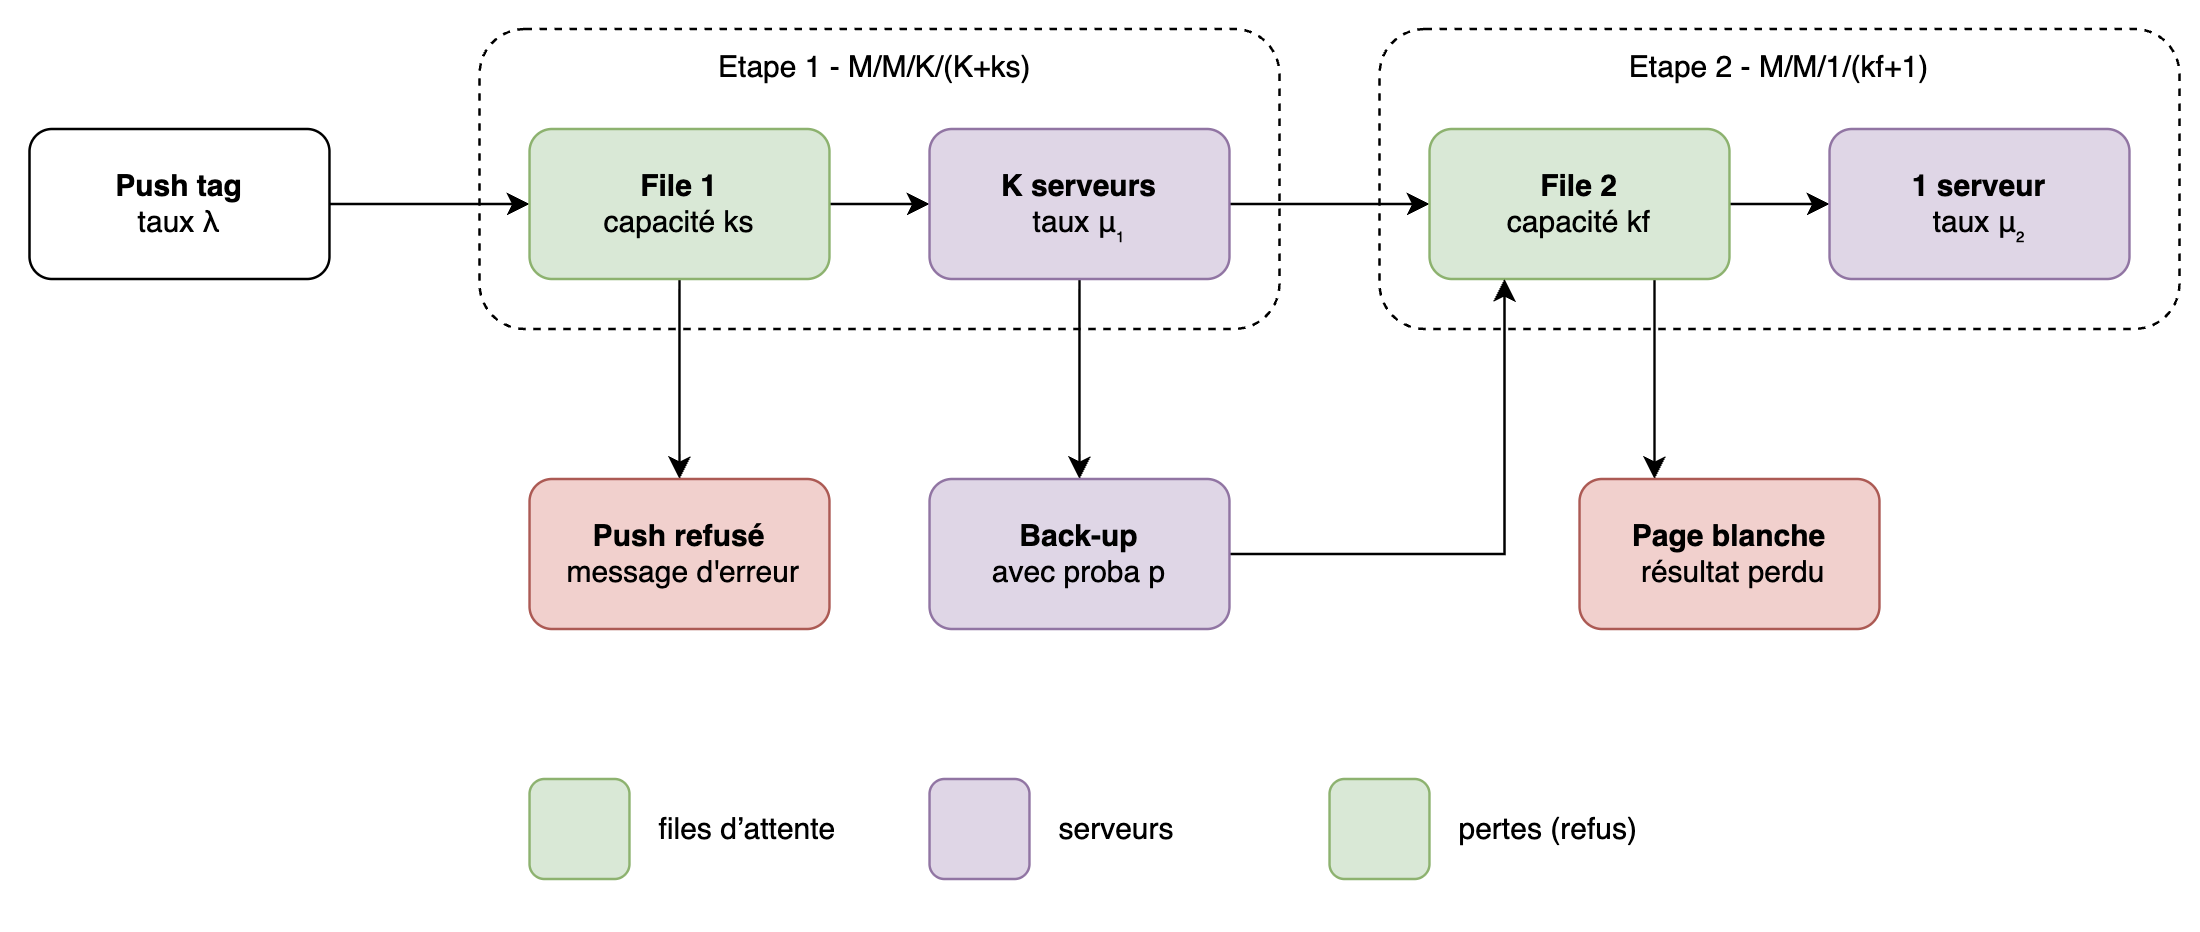

In [1]:
from IPython.display import Image
Image("../images/3.png")

# Simulations

Chaque point est une moyenne sur 30 réplications de 20 000 pushs, avec un IC à 95 %.

Paramètres : λ = 0,6, μ1 = 1/60, K = 40, ks = 60, kf = 3, et μ2 = 0,7 (ρ2 ≈ 0,86) ou μ2 = 0,5 (surcharge, ρ2 = 1,2). kf est petit pour que les pertes soient visibles.

In [2]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

sys.path.insert(0, str(Path.cwd().parent / "scripts"))
import WaterfallSimulation3
from Utils import Utils

LAM, MU1, K, KS, KF = 0.6, 1/60, 40, 60, 3
MU2, MU2_OVER = 0.7, 0.5
B, N_AGENTS = 30, 20_000
P_VALUES = [0, 0.2, 0.4, 0.6, 0.8, 0.9, 1]


def replicate(p, mu2):
    """Moyenne et demi-largeur de l'IC à 95 % des métriques du système, sur B réplications."""
    rows = []
    for b in range(B):
        s = WaterfallSimulation3.waterfall_simulation_3(
            LAM, MU1, K, mu2, KS, KF, p, np.random.default_rng(10 + b), test_z=N_AGENTS)
        s.run()
        stats, groups, backup = s.stats()['value'], s.sojourn_by_group(), s.backup_counts(100)
        rows.append({
            'blank': s.refusal_rate(2),
            'backup_mean': backup.mean(),
            'W': stats['mean_sojourn_time'],
            'var_W': stats['var_sojourn_time'],
            'W_rescued': groups.loc['rescued', 'mean_sojourn_time'],
            'W_others': groups.loc['others', 'mean_sojourn_time'],
        })
    df = pd.DataFrame(rows)
    return df.mean(), 1.96 * df.std(ddof=1) / np.sqrt(B)


def sweep(mu2):
    means, halves = zip(*[replicate(p, mu2) for p in P_VALUES])
    return pd.DataFrame(means, index=P_VALUES), pd.DataFrame(halves, index=P_VALUES)


res, ci = sweep(MU2)
res_over, ci_over = sweep(MU2_OVER)

### Simulation 1 : vérification

Avec p = 0 on doit retrouver les pertes exactes de la partie 2, avec p = 1 aucune perte.

In [3]:
p2_exact = Utils.tandem_blocking_exact(LAM, MU1, K, KS, MU2, KF)[1]

pd.DataFrame({
    'simulation': [f"{100 * res.loc[0, 'blank']:.2f} ± {100 * ci.loc[0, 'blank']:.2f}",
                   f"{100 * res.loc[1, 'blank']:.2f} ± {100 * ci.loc[1, 'blank']:.2f}"],
    'attendu': [f"{100 * p2_exact:.2f} (exact, partie 2)", "0"],
}, index=['pages blanches (%), p = 0', 'pages blanches (%), p = 1'])

,simulation,attendu
"pages blanches (%), p = 0",19.30 ± 0.15,"19.36 (exact, partie 2)"
"pages blanches (%), p = 1",0.00 ± 0.00,0


L'écart avec la valeur exacte est dans l'IC, et p = 1 ne perd plus rien.

### Simulation 2 : effet sur les pages blanches

Les pointillés donnent (1 − p) × les pertes de la partie 2, ce qu'on aurait si le back-up ne remplissait pas davantage la file 2.

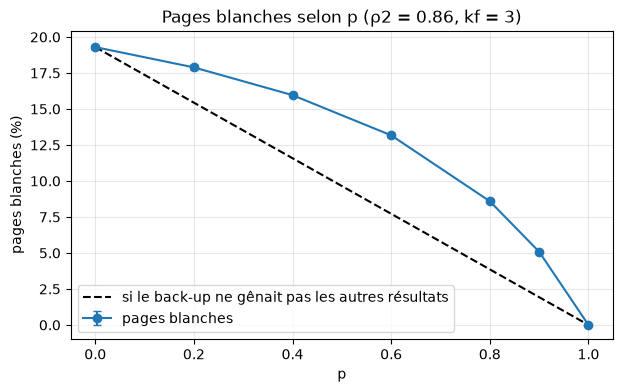

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.errorbar(P_VALUES, 100 * res['blank'], yerr=100 * ci['blank'], fmt='o-', capsize=3, label='pages blanches')
ax.plot(P_VALUES, 100 * (1 - np.array(P_VALUES)) * res.loc[0, 'blank'], 'k--', label='si le back-up ne gênait pas les autres résultats')
ax.set(xlabel='p', ylabel='pages blanches (%)', title=f'Pages blanches selon p (ρ2 = {LAM / MU2:.2f}, kf = {KF})')
ax.grid(alpha=.3)
ax.legend()
plt.show()

Les pages blanches baissent avec p, mais moins vite que prévu : 13,2 % pour p = 0,6 au lieu de 7,7 %. Les résultats sauvegardés restent dans la file 2 au lieu d'être perdus, elle est donc plus souvent pleine pour les autres.

### Simulation 3 : problèmes liés au back-up

À gauche, la taille du back-up sur une réplication. À droite, la part des résultats non sauvegardés qui sont perdus.

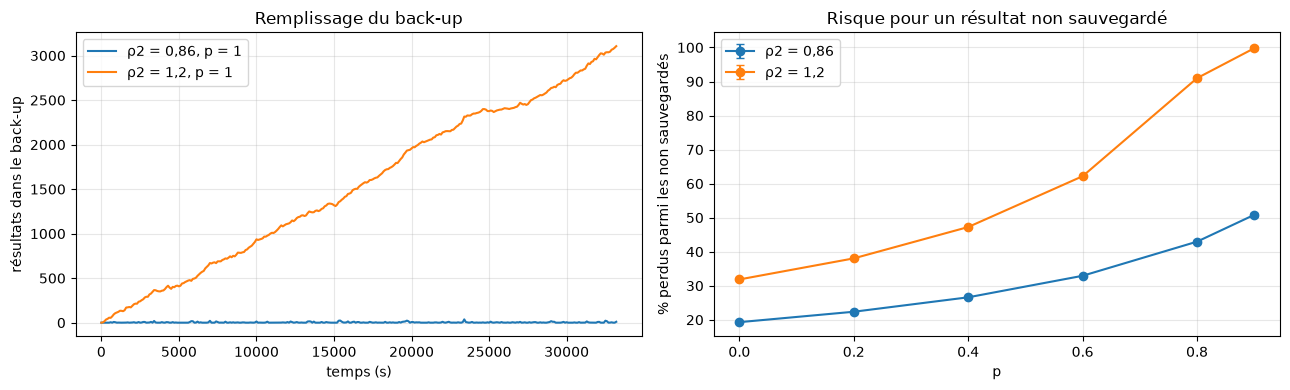

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for mu2, p, label in [(MU2, 1, 'ρ2 = 0,86, p = 1'), (MU2_OVER, 1, 'ρ2 = 1,2, p = 1')]:
    s = WaterfallSimulation3.waterfall_simulation_3(
        LAM, MU1, K, mu2, KS, KF, p, np.random.default_rng(10), test_z=N_AGENTS)
    s.run()
    backup = s.backup_counts(100)
    backup = backup[backup.index <= s.tops['t_arval_queue1'].max()]   # jusqu'au dernier push
    axes[0].plot(backup.index, backup, label=label)
axes[0].set(xlabel='temps (s)', ylabel='résultats dans le back-up', title='Remplissage du back-up')

p = np.array(P_VALUES[:-1])
for r, c, label in [(res, ci, 'ρ2 = 0,86'), (res_over, ci_over, 'ρ2 = 1,2')]:
    axes[1].errorbar(p, 100 * r['blank'][p] / (1 - p), yerr=100 * c['blank'][p] / (1 - p), fmt='o-', capsize=3, label=label)
axes[1].set(xlabel='p', ylabel='% perdus parmi les non sauvegardés', title='Risque pour un résultat non sauvegardé')

for ax in axes:
    ax.grid(alpha=.3)
    ax.legend()
plt.tight_layout()
plt.show()

À ρ2 = 0,86 le back-up reste presque vide. En surcharge avec p = 1, il grossit sans fin, comme la file infinie de la partie 1.

Plus p est grand, plus un résultat non sauvegardé risque d'être perdu : de 19 % à 51 % entre p = 0 et p = 0,9, presque 100 % en surcharge.

### Simulation 4 : back-up aléatoire ou systématique

En surcharge, le serveur de la file 2 envoie μ2 résultats par seconde et le back-up en reçoit p·λ(1 − P1). Le back-up reste donc borné si p < μ2 / (λ(1 − P1)) ≈ 0,84 (trait vertical).

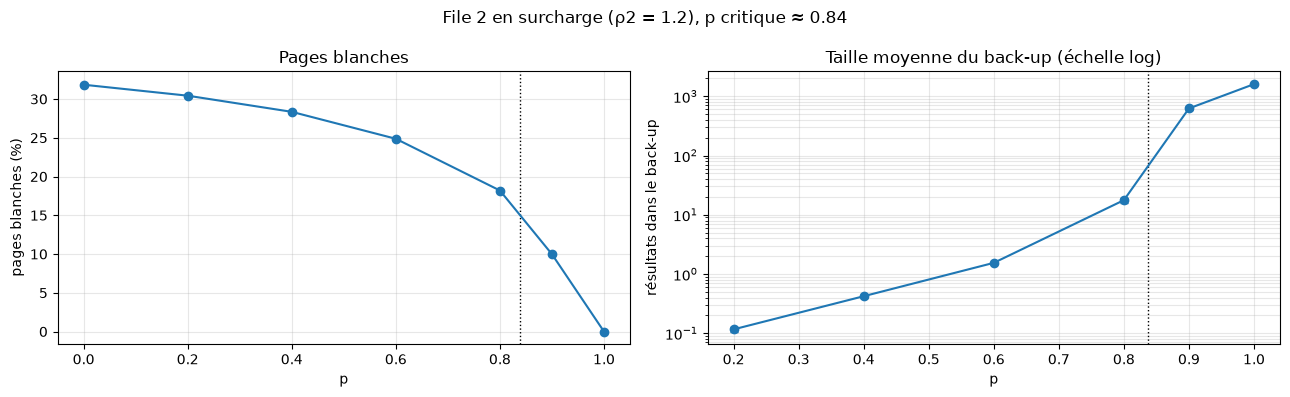

In [6]:
p1 = Utils.mmkn_blocking(LAM, MU1, K, KS)
p_crit = MU2_OVER / (LAM * (1 - p1))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].errorbar(P_VALUES, 100 * res_over['blank'], yerr=100 * ci_over['blank'], fmt='o-', capsize=3)
axes[0].set(xlabel='p', ylabel='pages blanches (%)', title='Pages blanches')
p = P_VALUES[1:]   # p = 0 : back-up vide, invisible en échelle log
axes[1].errorbar(p, res_over['backup_mean'][p], yerr=ci_over['backup_mean'][p], fmt='o-', capsize=3)
axes[1].set(xlabel='p', ylabel='résultats dans le back-up', yscale='log', title='Taille moyenne du back-up (échelle log)')
for ax in axes:
    ax.axvline(p_crit, color='k', ls=':', lw=1)
    ax.grid(alpha=.3, which='both')
fig.suptitle(f'File 2 en surcharge (ρ2 = {LAM / MU2_OVER:.1f}), p critique ≈ {p_crit:.2f}')
plt.tight_layout()
plt.show()

La simulation confirme le seuil. Pour p = 0,8, le back-up reste petit, les pages blanches passent de 32 % à 18 % et le temps de séjour de 68 s à 106 s. Au-delà, le back-up grossit sans limite et le temps de séjour atteint 22 min pour p = 0,9 et 55 min pour p = 1. Ces valeurs dépendent seulement de la durée simulée.

Un back-up systématique remplace donc les pertes par une attente sans limite, un back-up aléatoire sous le seuil reste borné.

### Simulation 5 : temps de séjour moyen et variance

ρ2 = 0,86. Seuls les résultats livrés sont comptés.

In [7]:
table = pd.DataFrame({
    'pages blanches (%)': 100 * res['blank'],
    'W moyen (s)': res['W'],
    'IC 95 %': ci['W'],
    'variance (s²)': res['var_W'],
    'écart-type (s)': np.sqrt(res['var_W']),
    'W sauvés (s)': res['W_rescued'],
    'W autres (s)': res['W_others'],
})
table.index.name = 'p'
table.round(2)

,pages blanches (%),W moyen (s),IC 95 %,variance (s²),écart-type (s),W sauvés (s),W autres (s)
p,,,,,,,
0.0,19.30,66.67,0.39,3659.75,60.50,NaN,66.67
0.2,17.89,66.83,0.39,3658.11,60.48,69.33,66.69
0.4,15.96,67.10,0.38,3658.61,60.49,69.89,66.71
0.6,13.17,67.69,0.38,3669.11,60.57,70.76,66.80
0.8,8.59,68.89,0.39,3671.25,60.59,72.33,66.84
0.9,5.08,70.29,0.42,3680.26,60.67,73.83,67.05
1.0,0.00,73.32,0.51,3720.94,61.00,77.06,67.33


Le temps de séjour moyen passe de 66,7 s à 73,3 s quand p va de 0 à 1, mais à p = 0, 19 % des étudiants ne reçoivent rien. Les résultats passés par le back-up mettent 69 à 77 s, contre environ 67 s pour les autres.

L'écart-type reste vers 61 s : il vient surtout des durées de test-suite (exponentielles de moyenne 60 s).

# Conclusion

Le back-up transforme des pertes en attente. Il réduit les pages blanches moins que prévu, et reste borné tant que p < μ2 / (λ(1 − P1)).

À charge normale, un back-up systématique coûte quelques secondes d'attente. En cas de pic, par exemple avant une deadline, il vaut mieux un p sous le seuil calculé pour le pic.

### Limites

- Back-up instantané, donc retards sous-estimés.
- Back-up infini, pas de disque plein.
- Hypothèses de la partie 2 : flux poissonnien, durées exponentielles, λ constant.

### Facteurs externes

Un résultat en retard vaut mieux qu'une page blanche s'il arrive avant la deadline. Un étudiant sans retour risque de re-pousser, ce qui augmente λ (non modélisé). Le back-up coûte du stockage à l'école, proportionnellement à p.